In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay, precision_recall_curve)


In [2]:
df=pd.read_csv("../dataset/paylater_kaggle.csv")
df.head(10)

C:\Users\j4m4l\AppData\Local\Temp\ipykernel_19852\1483679511.py:1: DtypeWarning: Columns (0: loanId) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("../dataset/paylater_kaggle.csv")


,loanId,clientIncome,incomeVerified,clientAge,clientGender,,clientLoanPurpose,clientResidentialStatus,clientTimeAtEmployer,clientNumberPhoneContacts,...,paymentRatio,firstPaymentDefault,loanDefault,loanIncomeRatio,applicationDateMonth,approvalDateMonth,disbursementDateMonth,repaidDateMonth,FirstPaymentDueDateMonth,dueDateMonth
0,PP99804128,66452.66,1,38,MALE,Married,education,Employer Provided,> 36 Months,458.000000,...,0.0,0,0,0.632029,5,5,5,5,6,8
1,PP99781446,35000.00,1,35,MALE,Single,other,Rented,> 36 Months,708.000000,...,0.0,0,0,0.571429,5,5,5,6,6,8
2,PP99274960,162851.11,1,47,FEMALE,Married,education,Own Residence,> 36 Months,622.000000,...,0.0,1,0,0.822837,5,5,5,6,6,8
3,PP97847695,55053.68,1,33,MALE,Single,other,Own Residence,> 36 Months,1289.979347,...,0.0,0,1,0.626661,5,5,5,5,6,8
4,PP97841916,32112.55,1,30,MALE,Single,house,Rented,> 36 Months,608.000000,...,0.0,1,0,0.622809,5,5,5,6,6,8
5,PP96645536,46760.64,1,45,MALE,Married,medical,Rented,> 36 Months,608.000000,...,0.0,0,0,0.630872,5,5,5,5,6,8
6,PP96235226,37890.77,1,34,MALE,Single,house,Rented,27-35 Months,451.000000,...,0.0,1,0,0.527833,5,5,5,6,6,8
7,PP95837939,55328.67,1,36,MALE,Single,house,Rented,> 36 Months,446.000000,...,0.0,0,0,0.487993,5,5,5,5,6,7
8,PP94055953,33318.13,1,32,FEMALE,Married,medical,Rented,> 36 Months,644.000000,...,0.0,0,0,0.630287,4,4,4,5,5,7
9,PP93977426,57404.62,1,42,MALE,Married,house,Own Residence,> 36 Months,430.000000,...,0.0,0,1,0.627127,5,5,5,5,6,8


In [3]:
print(f"Ukuran data: ", df.shape)
df.info()

Ukuran data:  (159596, 28)
<class 'pandas.DataFrame'>
RangeIndex: 159596 entries, 0 to 159595
Data columns (total 28 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   loanId                     159596 non-null  object 
 1   clientIncome               159596 non-null  float64
 2   incomeVerified             159596 non-null  int64  
 3   clientAge                  159596 non-null  int64  
 4   clientGender               159596 non-null  str    
 5                              159596 non-null  str    
 6   clientLoanPurpose          159596 non-null  str    
 7   clientResidentialStatus    159596 non-null  str    
 8   clientTimeAtEmployer       159596 non-null  str    
 9   clientNumberPhoneContacts  159596 non-null  float64
 10  clientAvgCallsPerDay       159596 non-null  float64
 11  loanNumber                 159596 non-null  int64  
 12  loanAmount                 159596 non-null  int64  
 13  interestRate 

## Eksplorasi Data (EDA)
Tujuan utama pengecekan kolom adalah untuk melihat apakah data Anda mengalami ketidakseimbangan kelas (class imbalance)—yang sangat umum terjadi pada kasus pendeteksian gagal bayar, di mana jumlah nasabah yang lancar (0) biasanya jauh lebih mendominasi dibandingkan nasabah yang gagal bayar (1).

In [4]:
print("Missing value per kolom")
print(df.isna().sum()[df.isna().sum()>0])
print()
print(df["loanDefault"].value_counts())
print(df["loanDefault"].value_counts(normalize=True).round(3))

Missing value per kolom
Series([], dtype: int64)

loanDefault
0    115321
1     44275
Name: count, dtype: int64
loanDefault
0    0.723
1    0.277
Name: proportion, dtype: float64


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
clientIncome,159596.0,90839.06,97280.33,30.00,35000.00,55116.21,105000.00,3925000.0
incomeVerified,159596.0,0.16,0.37,0.00,0.00,0.00,0.00,1.0
clientAge,159596.0,33.69,7.18,18.00,28.00,33.00,38.00,60.0
clientNumberPhoneContacts,159596.0,1262.06,1512.44,0.00,435.00,842.00,1532.00,60595.0
clientAvgCallsPerDay,159596.0,59.16,101.21,0.00,10.05,30.30,70.03,10994.5
loanNumber,159596.0,3.56,2.47,1.00,2.00,3.00,4.00,32.0
loanAmount,159596.0,35324.18,27840.82,11000.00,20000.00,25500.00,37500.00,500000.0
interestRate,159596.0,13.33,4.47,4.50,10.00,12.50,15.00,20.0
loanTerm,159596.0,85.39,39.32,60.00,60.00,60.00,90.00,180.0
maxAmountTaken,159596.0,0.71,0.46,0.00,0.00,1.00,1.00,1.0


Berdasarkan analisis statistik deskriptif di atas, kita dapat menyimpulkan bahwa dataset ini memiliki ukuran yang sangat memadai untuk melatih model machine learning dengan total hampir 160.000 baris data. Namun, terdapat beberapa catatan penting mengenai distribusi kelas target di mana sekitar 28% dari total nasabah mengalami gagal bayar (loanDefault), yang menunjukkan adanya ketidakseimbangan kelas (class imbalance) dan memerlukan perhatian khusus saat pemodelan nanti. Selain itu, ditemukan beberapa anomali data atau outlier ekstrem yang tidak wajar—seperti jumlah panggilan harian yang mencapai puluhan ribu serta nilai rasio pinjaman yang terlalu tinggi—sehingga proses pembersihan data (data cleaning) menjadi tahapan wajib sebelum data tersebut aman untuk diproses oleh algoritma.

data asli memang sering kali berantakan dan mengandung nilai-nilai ekstrem seperti itu. Meskipun data tersebut asli, bukan berarti data itu bisa langsung dimasukkan begitu saja ke dalam model machine learning.

In [6]:
max_calls_limit = df['clientAvgCallsPerDay'].quantile(0.99)
df['clientAvgCallsPerDay'] = df['clientAvgCallsPerDay'].clip(upper=max_calls_limit)

# Membatasi nilai rasio yang tidak masuk akal
max_ratio_limit = df['loanIncomeRatio'].quantile(0.99)
df['loanIncomeRatio'] = df['loanIncomeRatio'].clip(upper=max_ratio_limit)

# Menangani 'settleDays' (Nilai Negatif)
df['isEarlySettlement'] = df['settleDays'] < 0

print(df[['clientAvgCallsPerDay', 'loanIncomeRatio', 'settleDays']].describe().T.round(2))

                         count   mean    std    min    25%    50%    75%  \
clientAvgCallsPerDay  159596.0  56.53  76.14   0.00  10.05  30.30  70.03   
loanIncomeRatio       159596.0   0.67   0.56   0.01   0.29   0.51   0.91   
settleDays            159596.0  32.60  84.55 -32.00  -2.00   0.00  13.00   

                         max  
clientAvgCallsPerDay  444.03  
loanIncomeRatio         3.00  
settleDays            386.00  


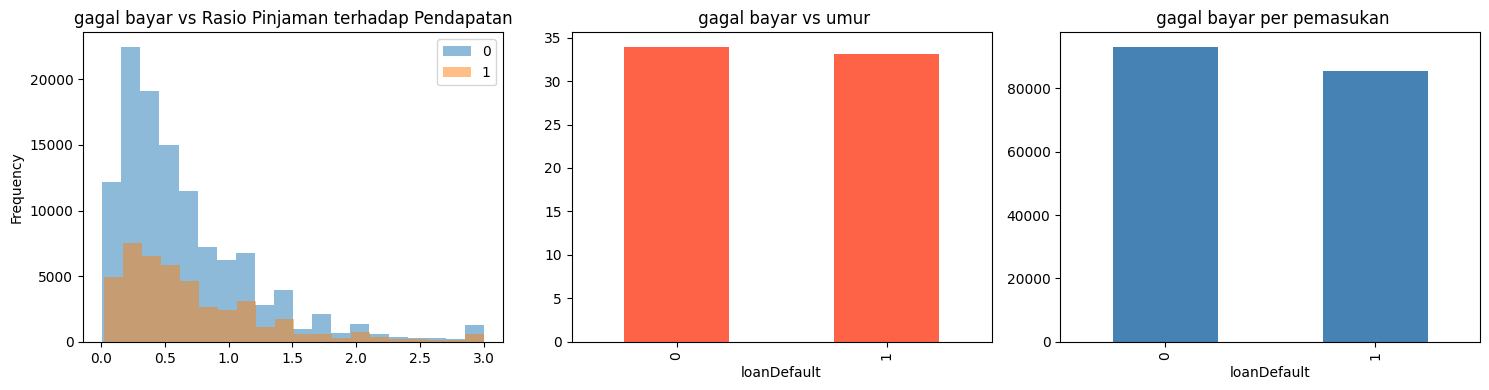

In [7]:
fig, ax = plt.subplots(1,3, figsize=(15, 4))
df.groupby("loanDefault")["loanIncomeRatio"].plot(kind="hist", alpha=0.5, bins=20, ax=ax[0], legend=True)
ax[0].set_title("gagal bayar vs Rasio Pinjaman terhadap Pendapatan")
df.groupby("loanDefault")["clientAge"].mean().plot(kind="bar", ax=ax[1], color="tomato")
ax[1].set_title(" gagal bayar vs umur")
df.groupby("loanDefault")["clientIncome"].mean().plot(kind="bar", ax=ax[2], color="steelblue")
ax[2].set_title(" gagal bayar per pemasukan")
plt.tight_layout(); plt.show()

## Preprocessing

In [8]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

target = "loanDefault"

x = df.drop(columns=[target, "loanId"])
y = df[target]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", x_train.shape, "Test :", x_test.shape)
print("Rasio gagal bayar train", round(y_test.mean(), 3),"| test", round(y_test.mean(),3))

Train: (127676, 27) Test : (31920, 27)
Rasio gagal bayar train 0.277 | test 0.277


In [9]:
fitur_num = x.select_dtypes(include="number").columns.to_list()
fitur_kat = x.select_dtypes(include="number").columns.to_list()
print("Numerik:", fitur_num)
print("Katergori:", fitur_kat)

prep_pohon = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), fitur_num),
    ("kat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), fitur_kat),
])

Numerik: ['clientIncome', 'incomeVerified', 'clientAge', 'clientNumberPhoneContacts', 'clientAvgCallsPerDay', 'loanNumber', 'loanAmount', 'interestRate', 'loanTerm', 'maxAmountTaken', 'maxTenorTaken', 'settleDays', 'paymentRatio', 'firstPaymentDefault', 'loanIncomeRatio', 'applicationDateMonth', 'approvalDateMonth', 'disbursementDateMonth', 'FirstPaymentDueDateMonth', 'dueDateMonth']
Katergori: ['clientIncome', 'incomeVerified', 'clientAge', 'clientNumberPhoneContacts', 'clientAvgCallsPerDay', 'loanNumber', 'loanAmount', 'interestRate', 'loanTerm', 'maxAmountTaken', 'maxTenorTaken', 'settleDays', 'paymentRatio', 'firstPaymentDefault', 'loanIncomeRatio', 'applicationDateMonth', 'approvalDateMonth', 'disbursementDateMonth', 'FirstPaymentDueDateMonth', 'dueDateMonth']


In [10]:
for depth in [2, 4, 6, 10, None]:
    m = Pipeline([("prep", prep_pohon),
                  ("clf", DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))])
    m.fit(x_train, y_train)
    auc_tr = roc_auc_score(y_train, m.predict_proba(x_train)[:, 1])
    auc_te = roc_auc_score(y_test, m.predict_proba(x_test)[:, 1])
    print(f"max_depth={str(depth):>4} | AUC train={auc_tr:.3f} | AUC test={auc_te:.3f}")

max_depth=   2 | AUC train=0.861 | AUC test=0.859
max_depth=   4 | AUC train=0.897 | AUC test=0.896
max_depth=   6 | AUC train=0.906 | AUC test=0.902
max_depth=  10 | AUC train=0.914 | AUC test=0.898
max_depth=None | AUC train=1.000 | AUC test=0.789


In [11]:
model_dt = Pipeline([("prep", prep_pohon),
                     ("clf", DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=RANDOM_STATE))])
model_dt.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['clientIncome','incomeVerified','clientAge',..., 'FirstPaymentDueDateMonth','dueDateMonth','isEarlySettlement']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('kat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

## Evaluasi Model

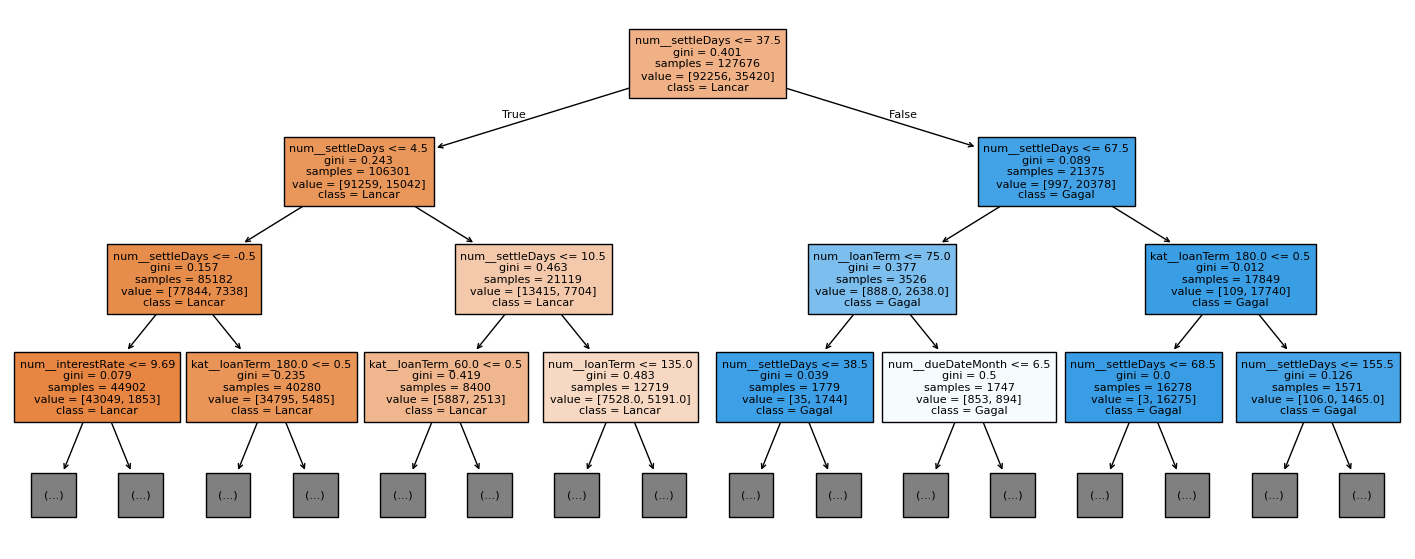

In [12]:
def evaluasi(nama, model, X_test, y_test, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"model": nama,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba)}

hasil = [evaluasi("Decision Tree", model_dt, x_test, y_test)]

nama_fitur = model_dt.named_steps["prep"].get_feature_names_out()
plt.figure(figsize=(18, 7))
plot_tree(model_dt.named_steps["clf"], max_depth=3, feature_names=nama_fitur,
          class_names=["Lancar", "Gagal"], filled=True, fontsize=8)
plt.show()

## SAVE MODEL

In [14]:
joblib.dump(model_dt, 'model_paylater_decition_tree.pkl')

['model_paylater_decition_tree.pkl']